In [2]:
import os
import cv2
import numpy as np 
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Đọc dữ liệu

In [ ]:
def load_images_from_folder(folder):
    images = []
    labels = []
    folder = Path(folder)
    class_names = sorted(
        [d.name for d in folder.iterdir() if d.is_dir() and d.name.isdigit()],
        key=int
    )
    for class_name in class_names:
        class_folder = folder / class_name
        for img_path in sorted(class_folder.glob('*.png')):
            img = cv2.imread(str(img_path))
            if img is None:
                continue
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            images.append(img)
            labels.append(int(class_name))
    return images, labels, class_names

In [5]:
train_dir = Path(r"C:\CS231\DATA\train")
images, labels, class_names = load_images_from_folder(train_dir)
print("Số ảnh:", len(images))
print("Số nhãn:", len(labels))
print("Các lớp:", class_names)
print("Nhãn ảnh đầu tiên:", labels[0])
print("Shape ảnh đầu tiên:", images[0].shape)

Số ảnh: 12494
Số nhãn: 12494
Các lớp: ['10000', '20000', '50000', '100000', '200000', '500000']
Nhãn ảnh đầu tiên: 10000
Shape ảnh đầu tiên: (640, 640, 3)


In [6]:
def extract_rgb_histogram(image, bins=256):
    feature_vector = []
    for i in range(3):
        hist = cv2.calcHist([image], [i], None, [bins], [0, 256])
        hist = cv2.normalize(hist, hist).flatten()
        feature_vector.extend(hist)
    return np.array(feature_vector)

# Trực quan hóa Histogram RGB

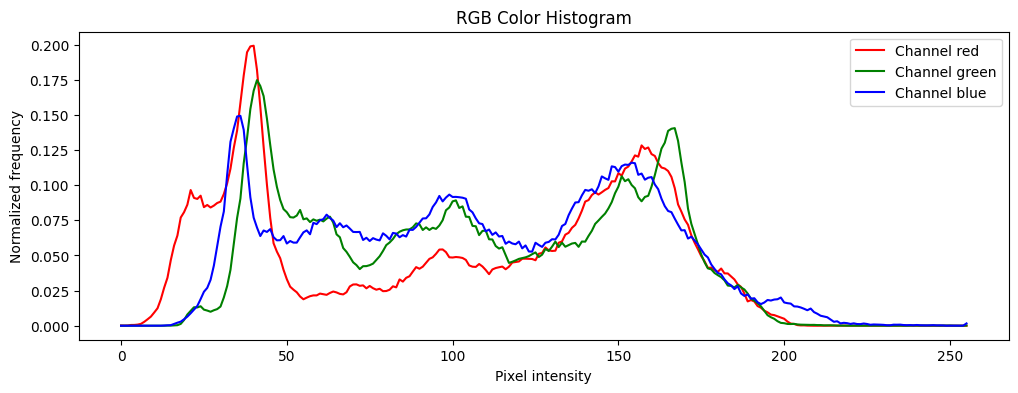

In [7]:
sample_rgb = images[0]
rgb_feature = extract_rgb_histogram(sample_rgb)
plt.figure(figsize=(12, 4))
colors = ['red', 'green', 'blue']
for i in range(3):
    start = i * 256
    end = (i + 1) * 256

    plt.plot(
        range(256),
        rgb_feature[start:end],
        color=colors[i],
        label=f"Channel {colors[i]}"
    )

plt.xlabel("Pixel intensity")
plt.ylabel("Normalized frequency")
plt.title("RGB Color Histogram")
plt.legend()
plt.show()


Trục X (Pixel intensity): Cường độ của từng kênh màu, từ 0 đến 255. Giá trị 0 là kênh màu không có cường độ, 255 là cường độ tối đa.

Trục Y: Giá trị histogram sau chuẩn hóa L2. Giá trị càng cao nghĩa là mức cường độ đó xuất hiện tương đối nhiều trong kênh tương ứng.

**Red**
- Đỉnh cao nhất khoảng 40, giá trị gần 0.20: Có sự tập trung mạnh các pixel có thành phần R gần 40

**Green**
- Hai vùng nổi bật khoảng 40 và 165: Thành phần G tập trung ở hai vùng cường độ khác nhau

**Blue**
- Đỉnh nổi bật khoảng 35, thêm vùng rộng 140–165: Thành phần B có nhiều giá trị thuộc các vùng này

**Quan sát 1: Có hai vùng cường độ nổi bật**

Cả ba kênh đều có mức tập trung đáng kể ở:
- Vùng cường độ thấp: khoảng 30-45
- Vùng cường độ trung bình đến khá cao: 140-170

Điều này cho thấy ảnh chứa những nhóm pixel có thành phần màu khác nhau, thay vì mọi pixel đều tập trung tại cùng một mức cường độ.

**Quan sát 2: Phân bố ba kênh không giống nhau**
- Đường đỏ, xanh lá và xanh dương có hình dạng khác nhau. Ví dụ, tại cường độ khoảng 100, đường xanh dương cao hơn đường đỏ.
- Điều đó nghĩa là cường độ 100 xuất hiện tương đối phổ biến hơn trong phân bố kênh B so với phân bố kênh R. Do từng kênh được chuẩn hóa L2 riêng, không thể trực tiếp kết luận rằng số pixel có B = 100 nhiều hơn số pixel có R = 100.

**Quan sát 3: Các giá trị gần 220-255 xuất hiện rất ít**
- Cả ba đường đều gần bằng 0 ở vùng cường độ cao này. Tức là số pixel có thành phần R, G hoặc B ở mức rất cao tương đối ít so với các mức cường độ nổi bật khác trong cùng kênh.

In [9]:
train_folder = Path(r'C:\CS231\DATA\train')
train_images,train_labels, train_class_names = load_images_from_folder(train_folder)

dev_folder = Path(r'C:\CS231\DATA\dev')
dev_images, dev_labels, dev_class_names = load_images_from_folder(dev_folder)

test_folder = Path(r'C:\CS231\DATA\test')
test_images, test_labels, test_class_names = load_images_from_folder(test_folder)

y_train = np.array(train_labels)
y_dev = np.array(dev_labels)
y_test = np.array(test_labels)

In [10]:
X_train_rgb = np.array([extract_rgb_histogram(img, bins=256) for img in train_images])
X_dev_rgb = np.array([extract_rgb_histogram(img, bins=256) for img in dev_images])
X_test_rgb = np.array([extract_rgb_histogram(img, bins=256) for img in test_images])

print(f"Kích thước tập train: {X_train_rgb.shape}, {y_train.shape}")
print(f"Kích thước tập dev: {X_dev_rgb.shape}, {y_dev.shape}")
print(f"Kích thước tập test: {X_test_rgb.shape}, {y_test.shape}")

Kích thước tập train: (12494, 768), (12494,)
Kích thước tập dev: (1564, 768), (1564,)
Kích thước tập test: (1553, 768), (1553,)


# Huấn luyện KNN

In [13]:
import sys
sys.path.insert(0, r"C:\CS231")

In [14]:
from itertools import product
from src.evaluation.value_metrics import evaluate_classification
import pandas as pd

n_neighbors_options = range(1, 11)
weight_options = ['uniform', 'distance']
metric_options = [
    'braycurtis',
    'canberra',
    'correlation',
    'euclidean',
    'minkowski'
]
results = []

for k, weight, metric in product(n_neighbors_options, weight_options, metric_options):
    knn = KNeighborsClassifier(
        n_neighbors=k,
        weights=weight,
        metric=metric,
        algorithm='brute'
    )
    knn.fit(X_train_rgb, y_train)
    y_pred = knn.predict(X_dev_rgb)
    scores = evaluate_classification(y_dev, y_pred)
    results.append({
        "k": k,
        "weights": weight,
        "metric": metric,
        "macro_f1": scores["macro_f1"],
        "mae_vnd": scores["mae_vnd"],
        "accuracy": scores["accuracy"]
    })
df_results = pd.DataFrame(results)
df_results = df_results.sort_values(
    by=["macro_f1", "mae_vnd"],
    ascending=[False, True],
    kind="stable"
).reset_index(drop=True)
display(df_results.head(10))

print("\nCấu hình tốt nhất:")
print(df_results.iloc[0])

,k,weights,metric,macro_f1,mae_vnd,accuracy
0,7,distance,canberra,0.673358,71815.856777,0.671995
1,8,distance,canberra,0.672434,71994.884910,0.671355
2,9,distance,canberra,0.669814,74303.069054,0.668159
3,6,distance,canberra,0.669573,72352.941176,0.668159
4,10,distance,canberra,0.668884,73209.718670,0.668798
5,6,uniform,canberra,0.662362,70019.181586,0.661765
6,4,distance,canberra,0.661415,73439.897698,0.660486
7,5,distance,canberra,0.660091,73714.833760,0.659207
8,10,uniform,canberra,0.659020,71195.652174,0.659207
9,8,uniform,canberra,0.657663,72129.156010,0.656010



Cấu hình tốt nhất:
k                      7
weights         distance
metric          canberra
macro_f1        0.673358
mae_vnd     71815.856777
accuracy        0.671995
Name: 0, dtype: object


In [15]:
best_by_metric = (
    df_results
    .drop_duplicates(subset="metric", keep="first")
    .sort_values("macro_f1", ascending=False)
)

display(
    best_by_metric[
        ["metric", "k", "weights",
         "macro_f1", "mae_vnd", "accuracy"]
    ]
)

,metric,k,weights,macro_f1,mae_vnd,accuracy
0,canberra,7,distance,0.673358,71815.856777,0.671995
19,braycurtis,8,distance,0.634552,79661.125320,0.634910
40,euclidean,8,distance,0.592152,87186.700767,0.591432
41,minkowski,8,distance,0.592152,87186.700767,0.591432
44,correlation,3,distance,0.591510,87966.751918,0.590793


In [16]:
cosine_results = []

for k, weight in product(n_neighbors_options, weight_options):
    knn = KNeighborsClassifier(
        n_neighbors=k,
        weights=weight,
        metric="cosine",
        algorithm="brute"
    )

    knn.fit(X_train_rgb, y_train)
    y_pred = knn.predict(X_dev_rgb)

    scores = evaluate_classification(y_dev, y_pred)

    cosine_results.append({
        "k": k,
        "weights": weight,
        "metric": "cosine",
        "macro_f1": scores["macro_f1"],
        "mae_vnd": scores["mae_vnd"],
        "accuracy": scores["accuracy"]
    })

df_cosine = pd.DataFrame(cosine_results)

display(df_cosine.sort_values("macro_f1", ascending=False).head())

,k,weights,metric,macro_f1,mae_vnd,accuracy
15,8,distance,cosine,0.597757,85971.867008,0.597187
13,7,distance,cosine,0.596022,86937.340153,0.595269
5,3,distance,cosine,0.589561,90159.846547,0.589514
7,4,distance,cosine,0.589014,89168.797954,0.588875
19,10,distance,cosine,0.588895,89328.644501,0.588875


In [ ]:
from itertools import product

# Khôi phục đầy đủ 6 metric
metric_options = [
    "braycurtis",
    "canberra",
    "correlation",
    "cosine",
    "euclidean",
    "minkowski"
]

n_neighbors_options = range(1, 11)
weight_options = ["uniform", "distance"]

# Tạo thứ tự thử nghiệm
grid_order = {
    (k, w, m): i
    for i, (k, w, m) in enumerate(
        product(
            n_neighbors_options,
            weight_options,
            metric_options
        )
    )
}

# Ghép 100 cấu hình ban đầu với 20 cấu hình cosine.
df_results = pd.concat([df_results, df_cosine], ignore_index=True)
df_results = df_results.drop_duplicates(["k", "weights", "metric"], keep="last")

# Gán thứ tự cho từng cấu hình
df_results["_order"] = [
    grid_order[(k, w, m)]
    for k, w, m in zip(
        df_results["k"],
        df_results["weights"],
        df_results["metric"]
    )
]

# Sắp xếp theo chuẩn đánh giá của dự án
df_results = (
    df_results
    .sort_values(
        ["macro_f1", "mae_vnd", "_order"],
        ascending=[False, True, True]
    )
    .drop(columns="_order")
    .reset_index(drop=True)
)

print("Tổng số cấu hình:", len(df_results))
display(df_results.head(10))

In [19]:
best_by_metric = (
    df_results
    .drop_duplicates(subset="metric")
    .sort_values("macro_f1", ascending=False)
)

display(best_by_metric)

,k,weights,metric,macro_f1,mae_vnd,accuracy
0,7,distance,canberra,0.673358,71815.856777,0.671995
19,8,distance,braycurtis,0.634552,79661.125320,0.634910
40,8,distance,cosine,0.597757,85971.867008,0.597187
42,8,distance,euclidean,0.592152,87186.700767,0.591432
43,8,distance,minkowski,0.592152,87186.700767,0.591432
46,3,distance,correlation,0.591510,87966.751918,0.590793


# Confusion matrix

In [20]:
best_knn_rgb = KNeighborsClassifier(
    n_neighbors=7,
    weights="distance",
    metric="canberra",
    algorithm="brute"
)

best_knn_rgb.fit(X_train_rgb, y_train)

y_pred_rgb = best_knn_rgb.predict(X_dev_rgb)

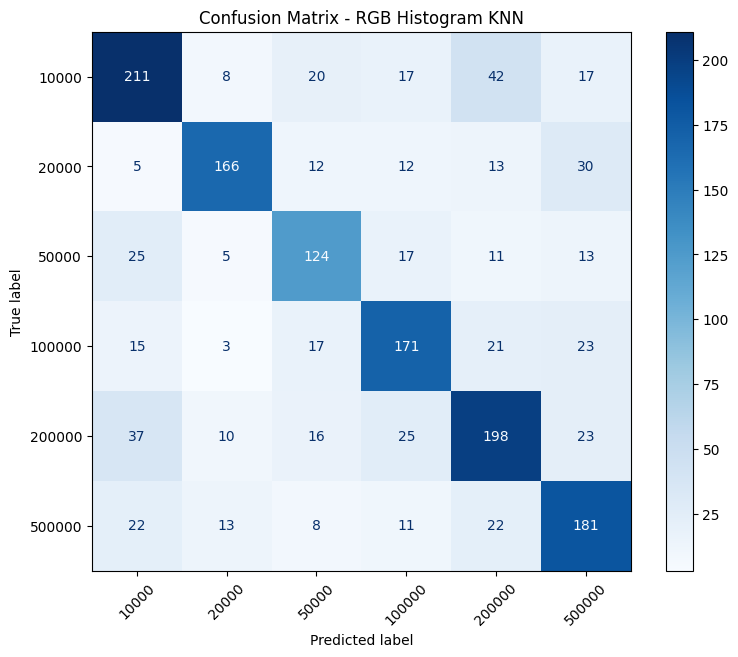

In [21]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

labels = np.sort(np.unique(y_train))

cm = confusion_matrix(
    y_dev,
    y_pred_rgb,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

fig, ax = plt.subplots(figsize=(9, 7))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45
)

plt.title("Confusion Matrix - RGB Histogram KNN")
plt.show()

Kết quả tổng thể:
- Accuracy: 67.20% (1051 / 1564 ảnh đúng)
- Macro-F1: 0.6734 
- MAE_VND: 71.816 VND / ảnh

Trong số 1.564 ảnh dev, mô hình phân loại đúng 1.051 ảnh và sai 513 ảnh. Tỷ lệ sai là khoảng 32,80%.

**Phân tích theo từng mệnh giá**


| Mệnh giá | Số ảnh đúng / tổng | Recall | F1-score |
| --- | --- | --- | --- |
| 10.000 | 211 / 315 | 67,0% | 0,670 |
| 20.000 | 166 / 238 | 69,7% | **0,749** |
| 50.000 | 124 / 195 | 63,6% | 0,633 |
| 100.000 | 171 / 250 | 68,4% | 0,680 |
| 200.000 | 198 / 309 | 64,1% | 0,643 |
| 500.000 | 181 / 257 | **70,4%** | 0,665 |

- Mệnh giá 20.000 VND có F1-score cao nhất, nghĩa là đang đạt sự cân bằng Precision và Recall tốt nhất trong sáu lớp.
- Mệnh giá 50.000 VND có F1-score thấp nhất, cho thấy Histogram RGB đang gặp nhiều khó khăn hơn trong việc phân biệt lớp này với các lớp còn lại.
- Riêng lớp 500.000 VND có Recall cao nhất nhưng Precision chỉ khoảng 63,1%. Nghĩa là mô hình tìm được khá nhiều ảnh 500.000 thật, nhưng cũng thường dự đoán nhầm ảnh thuộc mệnh giá khác thành 500.000.

**Các cặp mệnh giá bị nhầm nhiều nhất**
- 10.000 <-> 200.000: 79 ảnh
- 20.000 <-> 500.000: 43 ảnh
- 100.000 <-> 200.000: 46 ảnh

**Kết luận về RGB**
- Histogram RGB mô tả phân bố màu nhưng không nắm bắt được vị trí và cấu trúc họa tiết.
- Khi các tờ tiền khác mệnh giá có histogram màu tương tự, KNN có thể xem chúng là những hàng xóm gần nhau và đưa ra dự đoán sai.

### Nhận xét kết quả KNN với Histogram RGB

Sau khi thực hiện Grid Search trên tập dev, cấu hình KNN tốt nhất sử dụng `k=7`, `weights=distance` và `metric=canberra`, đạt Macro-F1 = 0,673358, Accuracy = 67,20% và MAE_VND = 71.815,86 VND.

Phân tích Confusion Matrix cho thấy mô hình phân loại đúng 1.051/1.564 ảnh. Mệnh giá 20.000 VND có F1-score cao nhất (0,749), trong khi mệnh giá 50.000 VND có F1-score thấp nhất (0,633). Đáng chú ý, mô hình thường nhầm lẫn giữa 10.000 và 200.000 VND với tổng cộng 79 trường hợp.

Kết quả cho thấy Histogram RGB có khả năng biểu diễn thông tin màu sắc phục vụ phân loại mệnh giá, nhưng vẫn tồn tại hạn chế đáng kể do không mô tả được cấu trúc và vị trí các họa tiết. Đây là cơ sở để tiếp tục thử nghiệm Histogram HSV, Color Moments và HOG.

In [ ]:
from pathlib import Path

output_dir = Path("results")
output_dir.mkdir(exist_ok=True)

df_results.to_csv(
    output_dir / "rgb_knn_grid_dev.csv",
    index=False
)


pd.DataFrame(
    cm,
    index=labels,
    columns=labels
).to_csv(output_dir / "rgb_confusion_matrix_dev.csv")